# DC4 511 keV imaging fit: simulated vs NF background

Same fit as the DC4 workflow (notebook 05 there): Richardson–Lucy image deconvolution, background shape fixed, normalization free. Only the background changes:

| fit | background |
|---|---|
| simulation | simulated components (notebook 08) |
| NF | NF templates |

Switch `INCLUDE_SAA` (Section 1):
- `True`: background = parts 01–05 (05 = SAA component, activation after the passages), original data. The realistic case.
- `False`: background = parts 01–04, SAA component removed from the data (exact only for simulated data).

Goal: how well the NF template works as the background of the fit, against the simulated background.

Caveats:
- The DC4 data contain the same simulated background events, so the simulation fit has the data's own noise: it is a reference, not a fair competitor. The NF template is the realistic case.
- Hypothesis (not verified): the DC4 data also contain ~21,500 counts at 511 keV that are in none of the parts, possibly Galactic diffuse emission (label d); the fit would put them into the sky image.
- 30 iterations instead of the DC4 15, so that both fits converge (`config/imagedeconvolution_gal_511keV_30it.yml`).

In [24]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Setup

In [25]:
import sys
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import cosipy as cp
from cosipy.image_deconvolution import DataIF_COSI_DC2, ImageDeconvolution
from histpy import Histogram

sys.path.insert(0, str(Path.cwd().parent.parent))     # project root, so `src` is importable
from src.plot_style import COLORS, PALETTE, set_global_style
from src.comparison_helpers import tidy_legends
set_global_style()                                    # after the cosipy import

# DC4 workflow code (your repo), loaded as "dc4" so it does not collide with this repo's "src"
DC4_SRC = Path("/Users/maura/Documents/COSI/data-challenge-4/workflow/src")
spec = importlib.util.spec_from_file_location("dc4", DC4_SRC / "__init__.py",
                                              submodule_search_locations=[str(DC4_SRC)])
dc4 = importlib.util.module_from_spec(spec)
sys.modules["dc4"] = dc4
spec.loader.exec_module(dc4)

paths = importlib.import_module("dc4.path_to_files")                     # DC4 inputs: weekly data, response, yaml configs
ResidualAnalysis = importlib.import_module("dc4.residuals").ResidualAnalysis
PlottingResiduals = importlib.import_module("dc4.plot_residuals").PlottingResiduals

%matplotlib inline

In [26]:
# Switch. True: background 01-05 (05 = SAA component) and the original data.
#         False: background 01-04 and the data with the SAA component removed (Section 2).
INCLUDE_SAA = True
PARTS = [1, 2, 3, 4, 5] if INCLUDE_SAA else [1, 2, 3, 4]
PART_LABEL = f"{PARTS[0]:02d}-{PARTS[-1]:02d}"

# Simulated background components, binned in notebook 08 (Galactic frame)
SIM_DIR = Path("../../data/background_components")
SIM_FILES = {part: f"part-{part:02d}_simulated_511keV_DC4binning_galactic.hdf5" for part in (1, 2, 3, 4, 5)}
SIM_PARTS = {part: SIM_DIR / SIM_FILES[part] for part in PARTS}
SAA_PATH = SIM_DIR / SIM_FILES[5]          # part 05 simulated: in the background, or removed from the data

# NF templates of the same parts (expected counts in the DC4 window, Galactic; scripts/compute_full_sky_template.py)
NF_DIR = Path("../../data/NF_background/template")
NF_PARTS = {part: NF_DIR / f"part-{part:02d}_FINAL_k2_511keV_DC4binning_galactic.hdf5" for part in PARTS}

print(f"INCLUDE_SAA = {INCLUDE_SAA}: parts {PART_LABEL}")
for part in PARTS:
    print(f"  part {part:02d}: simulation exists {SIM_PARTS[part].exists()} | NF template exists {NF_PARTS[part].exists()}")
if not INCLUDE_SAA:                                   # only then is part 05 removed from the data
    print(f"  SAA simulation (part 05, removed from the data): exists {SAA_PATH.exists()}")

# Deconvolution settings: copy of the DC4 yaml with iteration_max 30 (instead of 15)
DECONV_YAML = Path("../../config/imagedeconvolution_gal_511keV_30it.yml")
print("DC4 response:", paths.data_ext_response511_path.name, "| deconvolution yaml:", DECONV_YAML.name, DECONV_YAML.exists())

INCLUDE_SAA = True: parts 01-05
  part 01: simulation exists True | NF template exists True
  part 02: simulation exists True | NF template exists True
  part 03: simulation exists True | NF template exists True
  part 04: simulation exists True | NF template exists True
  part 05: simulation exists True | NF template exists True
DC4 response: extended_source_response_511_merged.h5 | deconvolution yaml: imagedeconvolution_gal_511keV_30it.yml True


## 2. Observed data

14 weeks, summed over time. With `INCLUDE_SAA = False` the SAA component is removed, so data and background contain the same components.

In [27]:
# The 14 weekly 511 keV observations (binned in the DC4 workflow), summed over time -> (Em, Phi, PsiChi)
observed = None
for week in paths.weekly_paths:
    bd = cp.BinnedData(paths.config_511_path)
    bd.load_binned_data_from_hdf5(binned_data=str(paths.data_dir_out / f"dc4_week_{week}_511_binned.hdf5"))
    h = bd.binned_data.project("Em", "Phi", "PsiChi").to_dense(copy=False)
    observed = h if observed is None else observed + h
print(observed.axes.labels, observed.shape, f"total {observed.contents.sum():,.0f} counts")

['Em' 'Phi' 'PsiChi'] (1, 60, 3072) total 1,576,953 counts


In [28]:
if INCLUDE_SAA:
    observed_with_saa = observed
    print("INCLUDE_SAA = True: observation kept as it is (the background includes part 05)")
else:
    # Remove the SAA component from the observation. Exact only because the mock data contain exactly these
    # simulated events: then observed - SAA >= 0 in every bin (checked here).
    saa = Histogram.open(SAA_PATH).project("Em", "Phi", "PsiChi").to_dense(copy=False)
    assert all(np.allclose(saa.axes[l].edges.value, observed.axes[l].edges.value) for l in ("Em", "Phi"))
    without_saa = np.asarray(observed.contents, dtype=float) - np.asarray(saa.contents, dtype=float)
    print(f"SAA component at 511 keV: {saa.contents.sum():,.0f} counts | "
          f"bins with observed < SAA: {(without_saa < 0).sum()} of {without_saa.size}")
    assert (without_saa >= 0).all(), "the observation does not contain these SAA events"
    observed_with_saa = observed                                    # kept for reference
    observed = Histogram(observed.axes, contents=without_saa)       # used by both fits from here on
    print(f"observed: {observed_with_saa.contents.sum():,.0f} -> {observed.contents.sum():,.0f} counts without SAA")

INCLUDE_SAA = True: observation kept as it is (the background includes part 05)


## 3. Backgrounds

All in the observation's binning (Galactic frame).

In [29]:
def galactic_cds(path):
    # Binned histogram (Time, Em, Phi, PsiChi) -> (Em, Phi, PsiChi), dense
    return Histogram.open(path).project("Em", "Phi", "PsiChi").to_dense(copy=False)

# Simulation: sum of the simulated components (parts in PARTS)
missing_sim = [part for part, path in SIM_PARTS.items() if not path.exists()]
assert not missing_sim, f"simulated parts {missing_sim} not binned yet: run notebook 08 (Section 3.2 for part 05)"
bkg_sim = {part: galactic_cds(path) for part, path in SIM_PARTS.items()}
bkg_sim_total = sum(bkg_sim.values())

# Same binning as the observation (required by the data interface)
for name, h in ((f"simulation {PART_LABEL}", bkg_sim_total),):
    same = all(np.allclose(h.axes[l].edges.value, observed.axes[l].edges.value) for l in ("Em", "Phi"))
    print(f"{name} axes {h.axes.labels}, Em/Phi edges as observed: {same}, "
          f"PsiChi {h.axes['PsiChi'].nside}/{h.axes['PsiChi'].scheme}/{h.axes['PsiChi'].coordsys.name}, "
          f"total {h.contents.sum():,.0f}")
for part, h in bkg_sim.items():
    print(f"  part {part:02d}: {h.contents.sum():,.0f}")
print(f"observed PsiChi {observed.axes['PsiChi'].nside}/{observed.axes['PsiChi'].scheme}/{observed.axes['PsiChi'].coordsys.name}")

simulation 01-05 axes ['Em' 'Phi' 'PsiChi'], Em/Phi edges as observed: True, PsiChi 16/RING/galactic, total 1,353,487
  part 01: 162,652
  part 02: 397,961
  part 03: 500,040
  part 04: 229,630
  part 05: 63,204
observed PsiChi 16/RING/galactic


In [30]:
# NF: sum of the NF templates (paths in Section 1)
missing = [part for part, path in NF_PARTS.items() if not path.exists()]
if missing:
    bkg_nf, bkg_nf_total = None, None
    print("NF templates not ready yet for parts", missing, "-> NF fit is skipped")
else:
    bkg_nf = {part: Histogram.open(path) for part, path in NF_PARTS.items()}   # already (Em, Phi, PsiChi), dense
    bkg_nf_total = sum(bkg_nf.values())
    same = all(np.allclose(bkg_nf_total.axes[l].edges.value, observed.axes[l].edges.value) for l in ("Em", "Phi"))
    print(f"NF {PART_LABEL}  Em/Phi edges as observed: {same}, total {bkg_nf_total.contents.sum():,.0f}")
    for part in NF_PARTS:
        print(f"  part {part:02d}: NF {bkg_nf[part].contents.sum():10,.0f} | sim {bkg_sim[part].contents.sum():10,.0f}")

NF 01-05  Em/Phi edges as observed: True, total 1,351,135
  part 01: NF    162,632 | sim    162,652
  part 02: NF    396,973 | sim    397,961
  part 03: NF    499,450 | sim    500,040
  part 04: NF    228,775 | sim    229,630
  part 05: NF     63,304 | sim     63,204


## 4. Response and fit setup

Galactic extended-source response (4.5 GB in memory). One data interface per background; same deconvolution yaml as DC4.

In [31]:
response_511 = Histogram.open(str(paths.data_ext_response511_path))
print(response_511.axes.labels, response_511.contents.shape)

['NuLambda' 'Ei' 'Em' 'Phi' 'PsiChi'] (3072, 1, 1, 60, 3072)


In [32]:
def setup_fit(name, background):
    # Data interface (observation + one background + response) and the deconvolution settings (DC4, 30 iterations)
    data_if = DataIF_COSI_DC2.load(name=name, event_binned_data=observed,
                                   dict_bkg_binned_data={"background": background},   # key used by the yaml norm range
                                   rsp=response_511, coordsys_conv_matrix=None)
    deconv = ImageDeconvolution()
    deconv.set_dataset([data_if])
    deconv.read_parameterfile(DECONV_YAML)
    return data_if, deconv


def fit_result(data_if, deconv):
    # Last iteration: image, background normalization, expected counts per CDS bin
    result = deconv.results[-1]
    expected = data_if.calc_expectation(result["model"], result["background_normalization"])
    return result, expected

In [33]:
def in_a_row(make_figure, analyses, colors, width=22):
    # One PlottingResiduals figure per analysis (show=False, titled with label=), placed side by side
    images = []
    for name, analysis in analyses.items():
        f = tidy_legends(make_figure(PlottingResiduals(analysis, color=colors[name]), name))
        f.canvas.draw()
        images.append(np.asarray(f.canvas.buffer_rgba()))
        plt.close(f)
    height = width * images[0].shape[0] / (images[0].shape[1] * len(images))
    fig, axes = plt.subplots(1, len(images), figsize=(width, height))
    for ax, image in zip(np.atleast_1d(axes), images):
        ax.imshow(image)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 5. Fit with the simulated background

In [34]:
data_if_sim, deconv_sim = setup_fit("511keV_sim", bkg_sim_total)
deconv_sim.initialize()
deconv_sim.run_deconvolution()
result_sim, expected_sim = fit_result(data_if_sim, deconv_sim)
print("iterations:", result_sim["iteration"], "| background norm:", result_sim["background_normalization"])

  0%|          | 0/30 [00:00<?, ?it/s]

iterations: 30 | background norm: {'background': 1.0017204353405988}


## 6. Fit with the NF templates

Same fit with the NF templates as background. Skipped until all templates in `PARTS` exist.

In [35]:
if bkg_nf_total is None:
    result_nf = None
    print("NF fit skipped: NF templates missing for parts", missing)
else:
    data_if_nf, deconv_nf = setup_fit("511keV_nf", bkg_nf_total)
    deconv_nf.initialize()
    deconv_nf.run_deconvolution()
    result_nf, expected_nf = fit_result(data_if_nf, deconv_nf)
    print("iterations:", result_nf["iteration"], "| background norm:", result_nf["background_normalization"])

  0%|          | 0/30 [00:00<?, ?it/s]

iterations: 30 | background norm: {'background': 1.0320282184304959}


## 7. Fit results

Summary table, convergence and reconstructed images of both fits (simulation and NF).

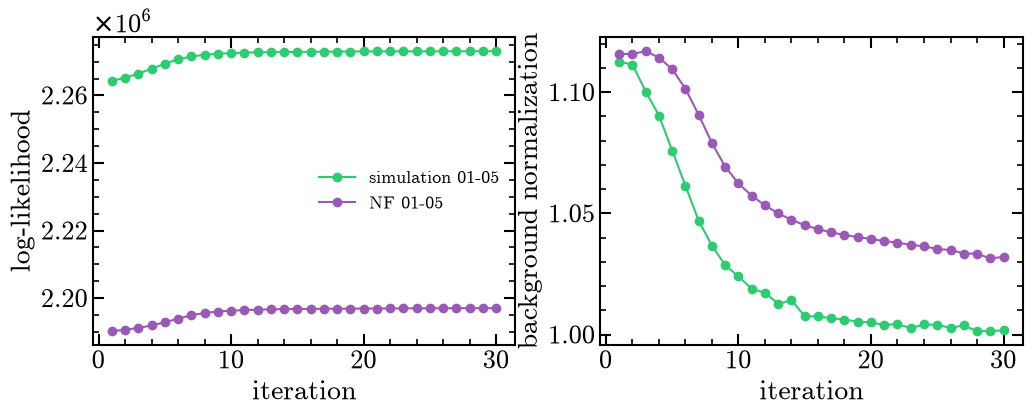

In [36]:
# Colours: simulation green, NF purple
FITS = {f"simulation {PART_LABEL}": (deconv_sim, result_sim, data_if_sim, PALETTE[1])}
if result_nf is not None:
    FITS[f"NF {PART_LABEL}"] = (deconv_nf, result_nf, data_if_nf, COLORS["nf"])

# Convergence: log-likelihood and background normalization per iteration
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, (deconv, _, _, color) in FITS.items():
    it = [r["iteration"] for r in deconv.results]
    ax1.plot(it, [r["log-likelihood"] for r in deconv.results], "o-", color=color, label=name)
    ax2.plot(it, [r["background_normalization"]["background"] for r in deconv.results], "o-", color=color, label=name)
ax1.set(xlabel="iteration", ylabel="log-likelihood")
ax2.set(xlabel="iteration", ylabel="background normalization")
ax1.legend()
plt.show()

In [37]:
# Summary of each fit: background normalization, log-likelihood, and how the counts are split
rows = []
for name, (_, result, data_if, _) in FITS.items():
    norm = result["background_normalization"]
    sky_counts = float(np.sum(data_if.calc_source_expectation(result["model"]).contents))
    bkg_counts = float(np.sum(data_if.calc_bkg_expectation(norm).contents))
    rows.append({"fit": name, "iterations": result["iteration"], "background norm": norm["background"],
                 "log-likelihood": float(np.sum(result["log-likelihood"])), "background counts": bkg_counts,
                 "sky counts": sky_counts, "observed counts": float(observed.contents.sum())})
summary = pd.DataFrame(rows).set_index("fit")
summary.style.format({"background norm": "{:.4f}", "log-likelihood": "{:,.0f}", "background counts": "{:,.0f}",
                      "sky counts": "{:,.0f}", "observed counts": "{:,.0f}"})

,iterations,background norm,log-likelihood,background counts,sky counts,observed counts
fit,,,,,,
simulation 01-05,30,1.0017,"2,273,090","1,355,816","222,014","1,576,953"
NF 01-05,30,1.0320,"2,197,043","1,394,409","186,825","1,576,953"


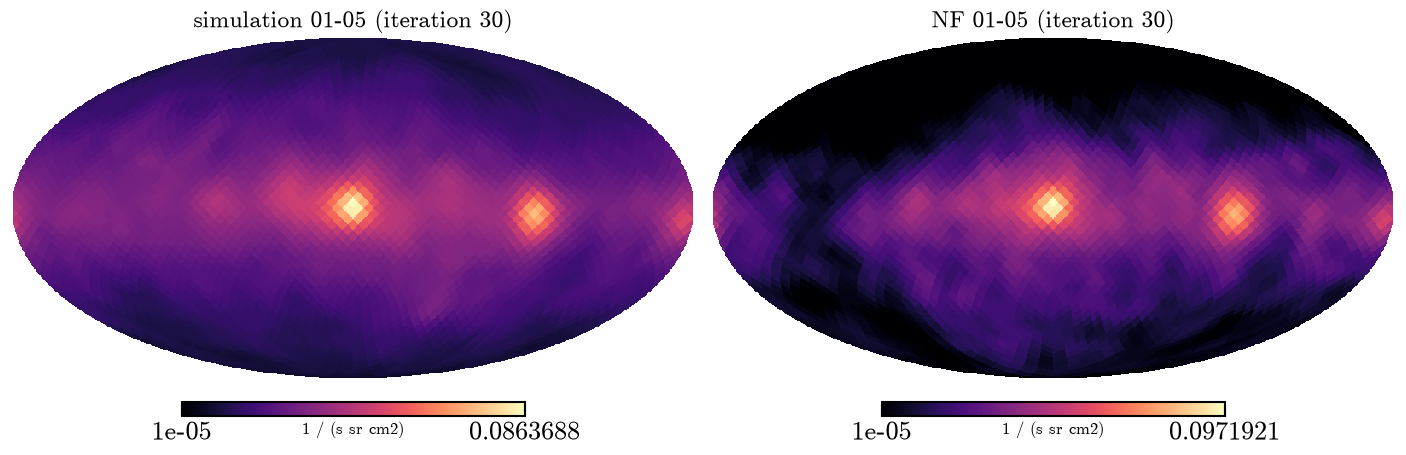

In [38]:
# Reconstructed 511 keV images (last iteration), same colour scale
fig = plt.figure(figsize=(14, 4.5))
for i, (name, (_, result, _, _)) in enumerate(FITS.items()):
    image = result["model"][:, 0].copy()
    image[image <= 0 * image.unit] = 1e-12 * image.unit
    hp.mollview(image.value, fig=fig.number, sub=(1, len(FITS), i + 1), min=1e-5, norm="log", cmap="magma",
                unit=str(image.unit), title=f"{name} (iteration {result['iteration']})")
plt.show()

## 8. Residuals of the fits

Your classes (`ResidualAnalysis`, `PlottingResiduals`), the two fits side by side. The simulation fit is only a reference: the data contain its events, so its residuals are artificially narrow. The NF fit is the one that tells how the template performs.

In [39]:
RESIDUALS = {"simulation fit (reference)": ResidualAnalysis(observed=observed, expected=expected_sim),
             "NF fit": ResidualAnalysis(observed=observed, expected=expected_nf)}
RESIDUAL_COLORS = {"simulation fit (reference)": PALETTE[1], "NF fit": COLORS["nf"]}   # green, purple


# Pearson statistics over all CDS bins (std ~ 1 if the fit describes the data down to the noise)
for name, ra in RESIDUALS.items():
    print(name)
    display(ra.statistics_table("pearson"))

Observed data have no time information; using atemporal residual analysis.
Observed data have no time information; using atemporal residual analysis.
simulation fit (reference)


,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,-0.001596,-0.076868,0.450908,0.450911,-1.705585,16.084643,0.386827,0.200195,37476.06393,27780.323587


NF fit


,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,-0.008085,-0.041904,0.978866,0.978899,-3.862684,11.41922,4.314779,0.495334,176623.434829,179875.193457


### 8.1 Phi

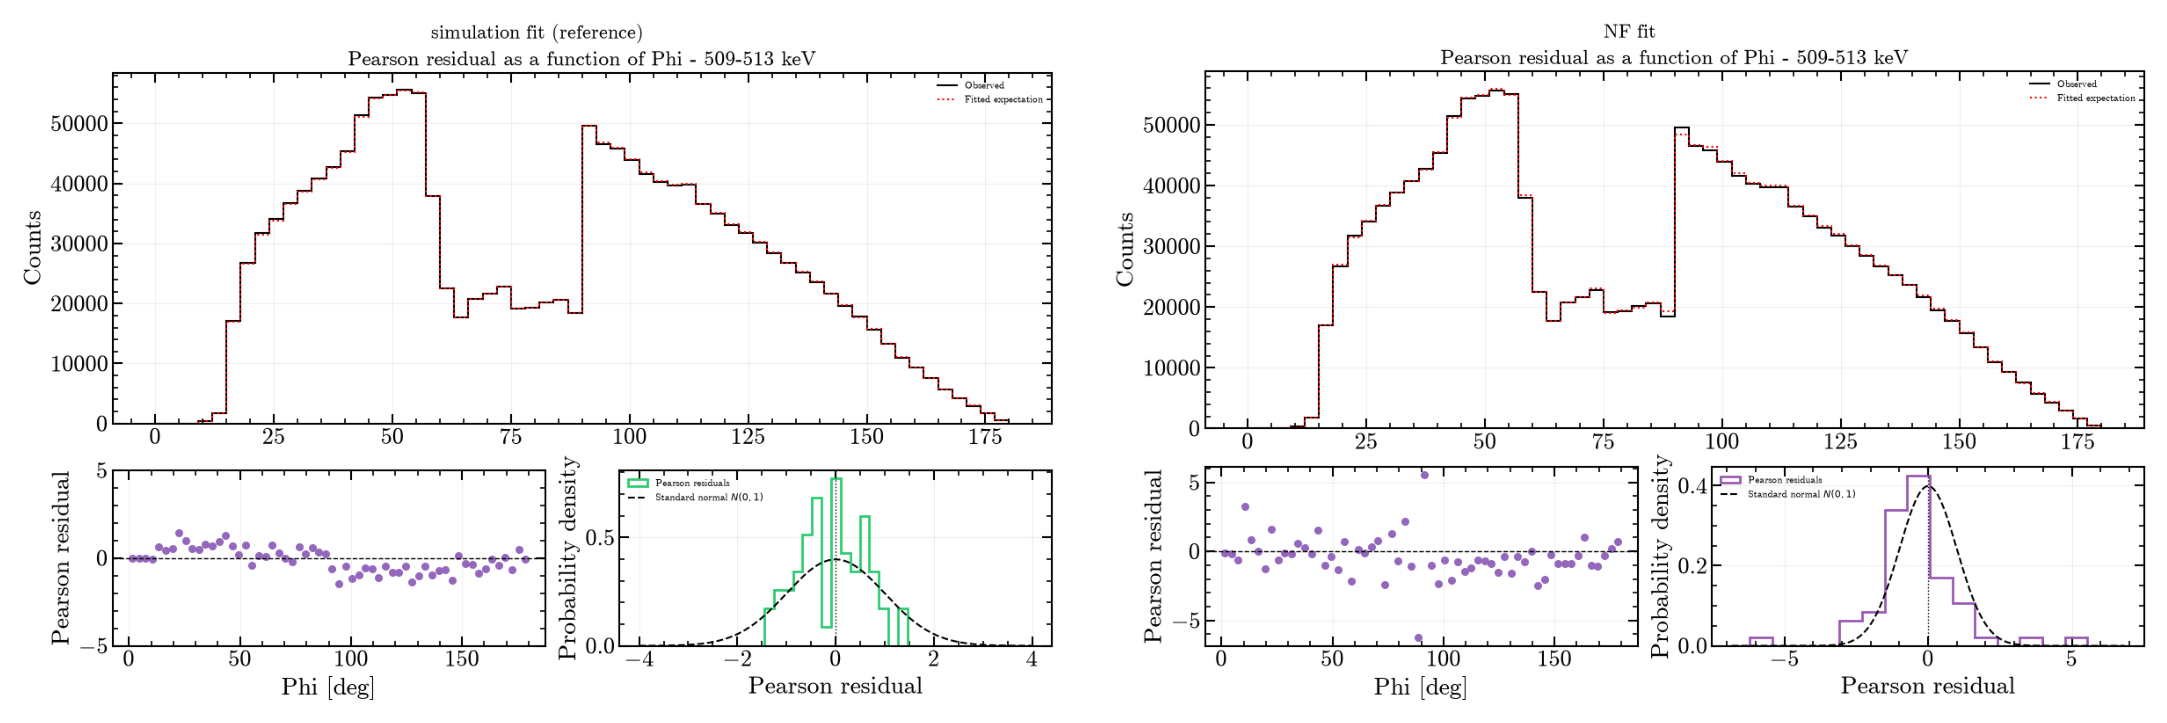

In [40]:
in_a_row(lambda pl, name: pl.plot("Phi_projection", residual_type="pearson", label=name, show=False,
                                  show_gaussian_reference=True), RESIDUALS, RESIDUAL_COLORS)

### 8.2 Sky (PsiChi, NSIDE 16)

Pearson residuals vs the standard normal N(0, 1).

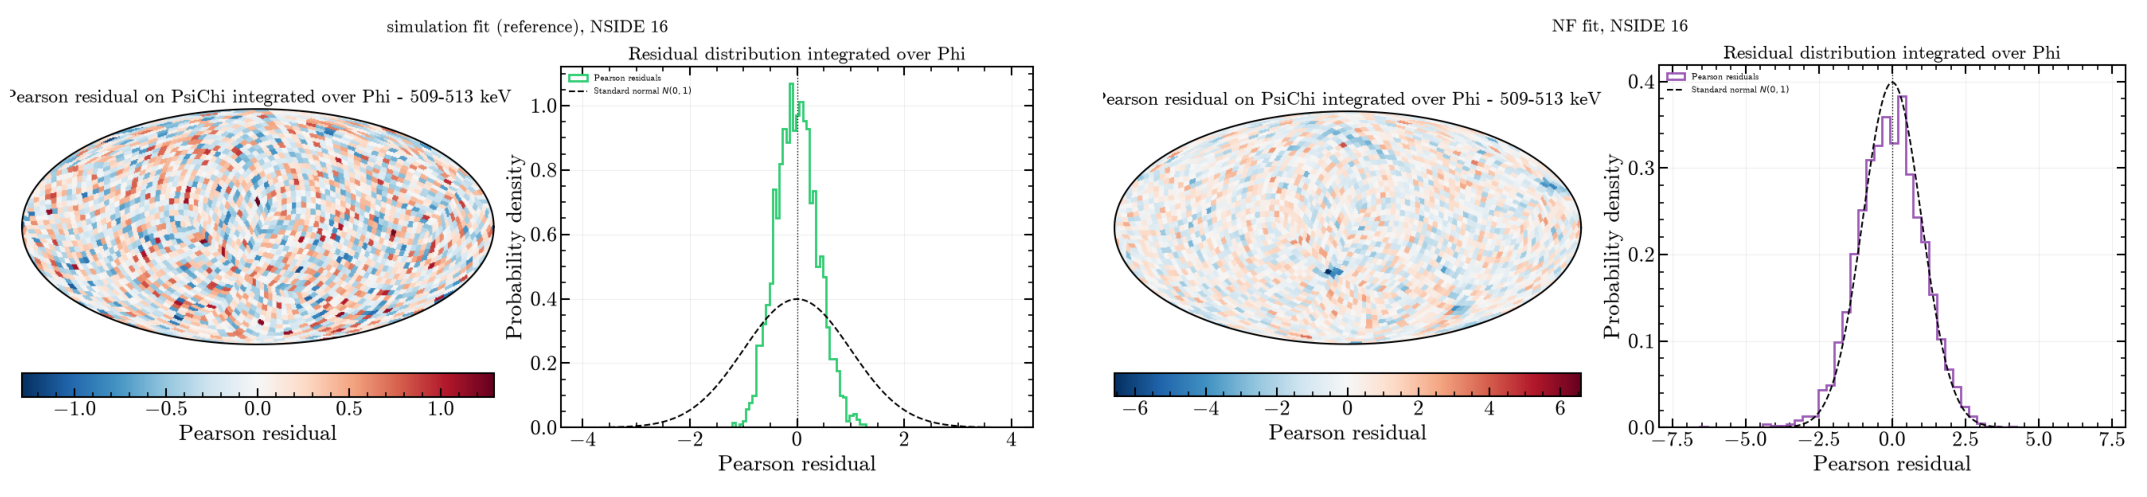

In [41]:
in_a_row(lambda pl, name: pl.plot("PsiChi_projection", residual_type="pearson", show_gaussian_reference=True,
                                  label=f"{name}, NSIDE 16", show=False), RESIDUALS, RESIDUAL_COLORS)

### 8.3 Sky, large scale (NSIDE 4)

Same residuals in pixels of ~15°. A good fit still gives std ≈ 1; a wider distribution means large-scale structure.

simulation fit (reference), NSIDE 4


,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,11520,-0.006976,-0.000288,0.37415,0.374215,-1.74623,3.042392,0.017361,0.008681,1613.223477,1601.059074


NF fit, NSIDE 4


,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,11520,-0.03047,-0.027313,0.989579,0.990048,-3.665332,5.029076,4.453125,0.364583,11291.851252,11351.405046


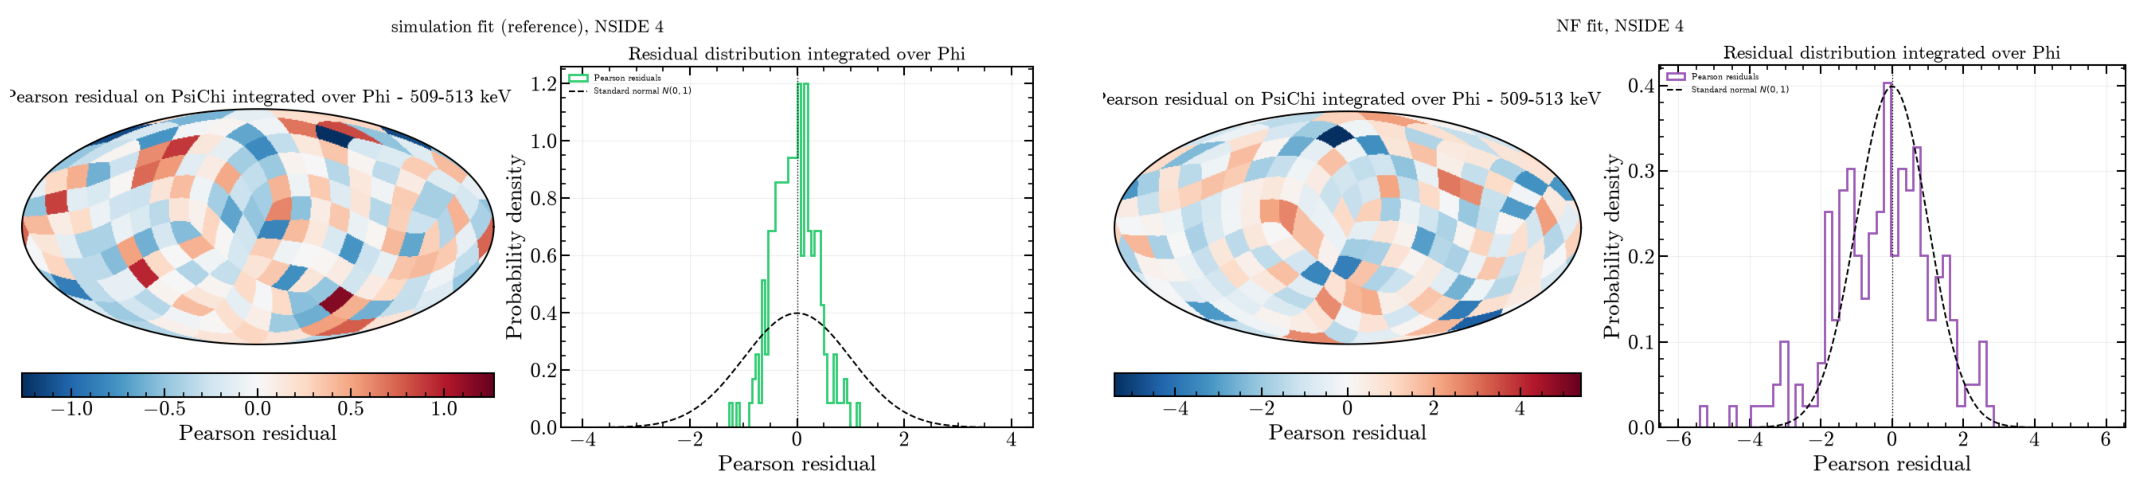

In [42]:
RESIDUALS_4 = {name: ra.degrade_psichi(4) for name, ra in RESIDUALS.items()}   # pixels of ~15 deg, counts summed
for name, ra in RESIDUALS_4.items():
    print(f"{name}, NSIDE 4")
    display(ra.statistics_table("pearson"))
in_a_row(lambda pl, name: pl.plot("PsiChi_projection", residual_type="pearson", show_gaussian_reference=True,
                                  label=f"{name}, NSIDE 4", show=False), RESIDUALS_4, RESIDUAL_COLORS)

## 9. Fitted backgrounds and sky images: simulation fit vs NF fit

Both fits model the same data as λ = R·S + β·B, so whatever one background takes, the sky image S gives up.
- Backgrounds: relative difference (β_NF·B_NF − β_sim·B_sim) / β_sim·B_sim. Noise scale: Poisson noise of the
  simulation, 1/√counts (the NF template is smooth).
- Sky: S_NF − S_sim.

Templates without fit (β = 1) against the simulation: notebook 10.

In [43]:
# Background of each fit: template x its fitted normalization (Sections 5 and 6), as arrays (Em, Phi, PsiChi)
norm_sim, norm_nf = result_sim["background_normalization"], result_nf["background_normalization"]
b_sim = np.asarray(data_if_sim.calc_bkg_expectation(norm_sim).to_dense().contents, dtype=float)
b_nf = np.asarray(data_if_nf.calc_bkg_expectation(norm_nf).to_dense().contents, dtype=float)
print(f"simulation fit: norm {norm_sim['background']:.4f}, background {bkg_sim_total.contents.sum():,.0f} -> {b_sim.sum():,.0f} counts")
print(f"NF fit:         norm {norm_nf['background']:.4f}, background {bkg_nf_total.contents.sum():,.0f} -> {b_nf.sum():,.0f} counts")
print(f"NF / simulation - 1: {b_nf.sum() / b_sim.sum() - 1:+.2%}")

simulation fit: norm 1.0017, background 1,353,487 -> 1,355,816 counts
NF fit:         norm 1.0320, background 1,351,135 -> 1,394,409 counts
NF / simulation - 1: +2.85%


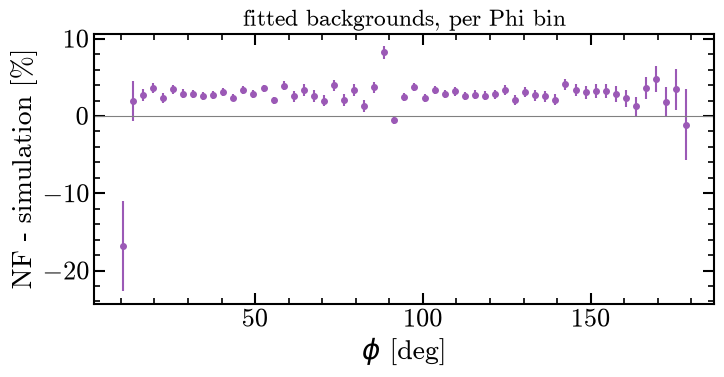

In [49]:
# Relative difference per Phi bin (summed over Em and the sky); error bars = Poisson noise of the simulation
phi_edges = observed.axes["Phi"].edges.to_value("deg")
phi_centres = 0.5 * (phi_edges[1:] + phi_edges[:-1])
b_sim_phi, b_nf_phi = b_sim.sum(axis=(0, 2)), b_nf.sum(axis=(0, 2))
ok = b_sim_phi > 0                                                     # bins below ~10 deg are empty

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(phi_centres[ok], 100 * (b_nf_phi[ok] / b_sim_phi[ok] - 1), yerr=100 / np.sqrt(b_sim_phi[ok]),
            fmt="o", ms=4, color=COLORS["nf"])
ax.axhline(0, color=COLORS["ref"], lw=0.8)
ax.set(xlabel=r"$\phi$ [deg]", ylabel="NF - simulation [%]", title="fitted backgrounds, per Phi bin")
plt.show()

NSIDE 16: NF - simulation median +2.82%, std 5.61% | Poisson noise of the simulation per pixel (median) 4.75%
NSIDE  4: NF - simulation median +2.63%, std 1.81% | Poisson noise of the simulation per pixel (median) 1.19%


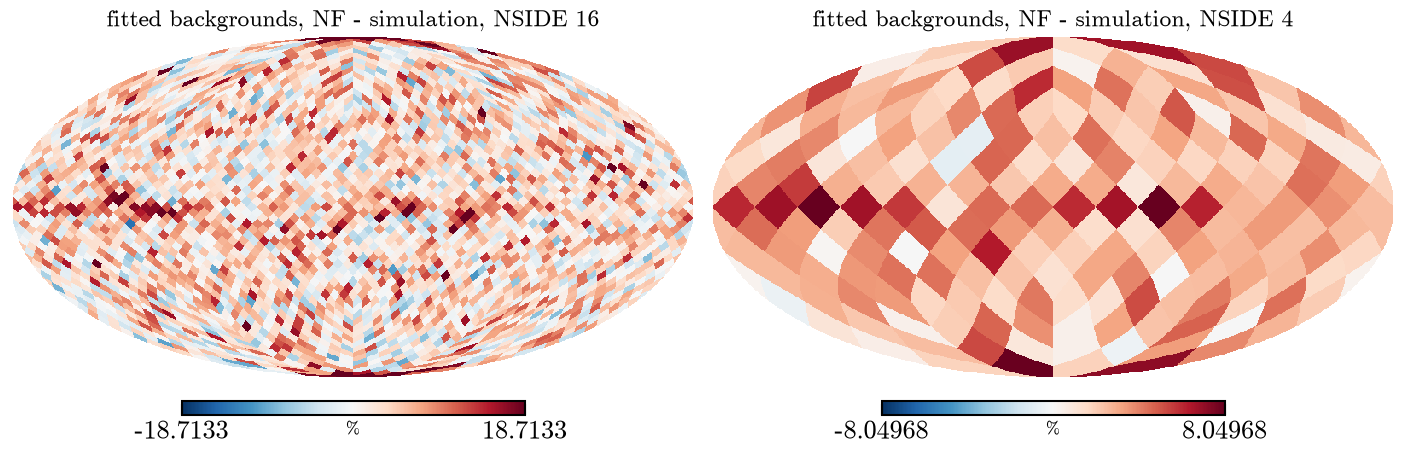

In [48]:
# Relative difference per sky pixel (summed over Em and Phi), NSIDE 16 and NSIDE 4 (~15 deg pixels, counts summed)
nside = observed.axes["PsiChi"].nside
b_sim_pix, b_nf_pix = b_sim.sum(axis=(0, 1)), b_nf.sum(axis=(0, 1))
fig = plt.figure(figsize=(14, 4.5))
for i, ns in enumerate((nside, 4)):
    s = b_sim_pix if ns == nside else hp.ud_grade(b_sim_pix, ns, power=-2)   # power=-2: counts are summed
    n = b_nf_pix if ns == nside else hp.ud_grade(b_nf_pix, ns, power=-2)
    rel = 100 * (n / s - 1)
    print(f"NSIDE {ns:2d}: NF - simulation median {np.median(rel):+.2f}%, std {rel.std():.2f}% | "
          f"Poisson noise of the simulation per pixel (median) {100 * np.median(1 / np.sqrt(s)):.2f}%")
    lim = np.percentile(np.abs(rel), 99)
    hp.mollview(rel, fig=fig.number, sub=(1, 2, i + 1), cmap="RdBu_r", min=-lim, max=lim, unit="%",
                title=f"fitted backgrounds, NF - simulation, NSIDE {ns}")
plt.show()

sky counts: simulation fit 222,014 | NF fit 186,825 | NF / simulation 0.841


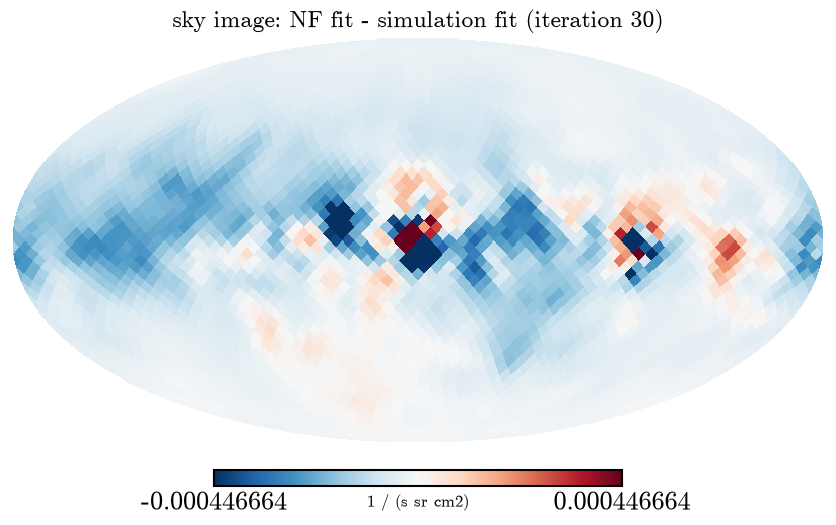

In [47]:
# Sky images of the two fits (last iteration): difference NF - simulation; sky counts from the summary (Section 7)
sky = summary["sky counts"]
print(f"sky counts: simulation fit {sky.iloc[0]:,.0f} | NF fit {sky.iloc[1]:,.0f} | NF / simulation {sky.iloc[1] / sky.iloc[0]:.3f}")

image_sim, image_nf = result_sim["model"][:, 0], result_nf["model"][:, 0]
diff = (image_nf - image_sim).value
lim = np.percentile(np.abs(diff), 99)
hp.mollview(diff, cmap="RdBu_r", min=-lim, max=lim, unit=str(image_sim.unit),
            title=f"sky image: NF fit - simulation fit (iteration {result_nf['iteration']})")
plt.show()